In [ ]:

import pandas as pd
import numpy as np
import pickle
import re
from pathlib import Path

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix
)

from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, Bidirectional, LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

# -------------------------------
# 1. Load and clean the dataset
# -------------------------------
BASE_DIR = Path(__file__).resolve().parent.parent
MODEL_DIR = BASE_DIR / "models"
MODEL_DIR.mkdir(exist_ok=True)

df = pd.read_csv(BASE_DIR / "dataset.csv")

df = df.dropna(subset=["Text", "language"]).copy()
df["Text"] = df["Text"].astype(str).str.strip()
df["language"] = df["language"].astype(str).str.strip()
df = df[(df["Text"] != "") & (df["language"] != "")]
df = df.drop_duplicates(subset=["Text", "language"])

print("Dataset shape after cleaning:", df.shape)
print("Number of languages:", df["language"].nunique())

# -------------------------------
# 2. Encode language labels
# -------------------------------
label_encoder = LabelEncoder()
y = label_encoder.fit_transform(df["language"])

X_train, X_test, y_train, y_test = train_test_split(
    df["Text"].to_numpy(),
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# -------------------------------
# 3. Character tokenization
# -------------------------------
MAX_VOCAB = 5000
MAX_LEN = 300

tokenizer = Tokenizer(
    num_words=MAX_VOCAB,
    char_level=True,
    lower=False,
    filters=""
)

tokenizer.fit_on_texts(X_train)

X_train_seq = tokenizer.texts_to_sequences(X_train)
X_test_seq = tokenizer.texts_to_sequences(X_test)

X_train_pad = pad_sequences(
    X_train_seq, maxlen=MAX_LEN, padding="post", truncating="post"
)
X_test_pad = pad_sequences(
    X_test_seq, maxlen=MAX_LEN, padding="post", truncating="post"
)

vocab_size = min(MAX_VOCAB, len(tokenizer.word_index) + 1)
num_classes = len(label_encoder.classes_)

print("Vocabulary size:", vocab_size)
print("Training samples:", len(X_train_pad))
print("Testing samples:", len(X_test_pad))

# -------------------------------
# 4. Build the LSTM model
# -------------------------------
model = Sequential([
    Embedding(input_dim=vocab_size, output_dim=32, mask_zero=True),
    Bidirectional(LSTM(64)),
    Dropout(0.3),
    Dense(64, activation="relu"),
    Dropout(0.2),
    Dense(num_classes, activation="softmax")
])

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

# -------------------------------
# 5. Train the model
# -------------------------------
early_stop = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

history = model.fit(
    X_train_pad,
    y_train,
    validation_split=0.1,
    epochs=15,
    batch_size=64,
    callbacks=[early_stop],
    verbose=1
)

# -------------------------------
# 6. Evaluate on unseen test data
# -------------------------------
probabilities = model.predict(X_test_pad, verbose=0)
y_pred = np.argmax(probabilities, axis=1)

accuracy = accuracy_score(y_test, y_pred)
print(f"\nTest Accuracy: {accuracy * 100:.2f}%")

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    labels=np.arange(num_classes),
    target_names=label_encoder.classes_,
    zero_division=0
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

# Show actual vs predicted examples
print("\nActual vs Predicted:")
for text, actual, predicted in zip(X_test[:15], y_test[:15], y_pred[:15]):
    print(f"Text: {text[:90]}")
    print(f"Actual: {label_encoder.inverse_transform([actual])[0]}")
    print(f"Predicted: {label_encoder.inverse_transform([predicted])[0]}")
    print("-" * 40)

# -------------------------------
# 7. Save model and preprocessing
# -------------------------------
model.save(MODEL_DIR / "language_lstm.keras")

with open(MODEL_DIR / "tokenizer.pkl", "wb") as f:
    pickle.dump(tokenizer, f)

with open(MODEL_DIR / "label_encoder.pkl", "wb") as f:
    pickle.dump(label_encoder, f)

print("\nModel and preprocessing files saved in the models folder.")


NameError: name '__file__' is not defined

In [ ]:
import pandas as pd

df = pd.read_csv("/content/dataset.csv", encoding="utf-8")
print(df.shape)
print(df.columns.tolist())
print(df.head())

(3474, 2)
['Text', 'language']
                                                Text  language
0  klement gottwaldi surnukeha palsameeriti ning ...  Estonian
1  sebes joseph pereira thomas  på eng the jesuit...   Swedish
2  ถนนเจริญกรุง อักษรโรมัน thanon charoen krung เ...      Thai
3  விசாகப்பட்டினம் தமிழ்ச்சங்கத்தை இந்துப் பத்திர...     Tamil
4  de spons behoort tot het geslacht haliclona en...     Dutch


In [ ]:

import os
import pickle
import random
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Bidirectional, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

DATA_PATH = Path("/content/dataset.csv")
MODEL_DIR = Path("/content/models")
MODEL_DIR.mkdir(parents=True, exist_ok=True)

MAX_VOCAB = 5000
MAX_LEN = 300
BATCH_SIZE = 64
EPOCHS = 15

print("TensorFlow:", tf.__version__)
print("Dataset exists:", DATA_PATH.exists())

if not DATA_PATH.exists():
    raise FileNotFoundError(
        "dataset.csv not found. Upload it using the Colab Files panel."
    )


TensorFlow: 2.21.0
Dataset exists: True


In [ ]:

df = pd.read_csv(DATA_PATH, encoding="utf-8")

print("Original dataset shape:", df.shape)
print("Original columns:", df.columns.tolist())

# Handle column names with accidental spaces
df.columns = df.columns.str.strip()

required_columns = {"Text", "language"}
if not required_columns.issubset(df.columns):
    raise ValueError(
        f"Dataset must contain columns {required_columns}. "
        f"Found: {df.columns.tolist()}"
    )

df = df[["Text", "language"]].copy()

df["Text"] = df["Text"].astype("string").str.strip()
df["language"] = df["language"].astype("string").str.strip()

df = df.dropna(subset=["Text", "language"])
df = df[
    (df["Text"] != "") &
    (df["language"] != "")
]
df = df.drop_duplicates(subset=["Text", "language"])
df = df.reset_index(drop=True)

if df["language"].nunique() < 2:
    raise ValueError("At least two language classes are required.")

print("\nCleaned dataset shape:", df.shape)
print("\nLanguage counts:")
print(df["language"].value_counts().sort_index())
print("\nSample records:")
print(df.head())


Original dataset shape: (3474, 2)
Original columns: ['Text', 'language']

Cleaned dataset shape: (3462, 2)

Language counts:
language
Arabic        144
Chinese       152
Dutch         169
English       165
Estonian      149
French        156
Hindi         171
Indonesian    149
Japanese      163
Korean        154
Latin         158
Persian       159
Portugese     161
Pushto        151
Romanian      147
Russian       169
Spanish       161
Swedish       174
Tamil         145
Thai          158
Turkish       165
Urdu          142
Name: count, dtype: Int64

Sample records:
                                                Text  language
0  klement gottwaldi surnukeha palsameeriti ning ...  Estonian
1  sebes joseph pereira thomas  på eng the jesuit...   Swedish
2  ถนนเจริญกรุง อักษรโรมัน thanon charoen krung เ...      Thai
3  விசாகப்பட்டினம் தமிழ்ச்சங்கத்தை இந்துப் பத்திர...     Tamil
4  de spons behoort tot het geslacht haliclona en...     Dutch


In [ ]:

X = df["Text"].astype(str).to_numpy()
y_text = df["language"].astype(str).to_numpy()

label_encoder = LabelEncoder()
y = label_encoder.fit_transform(y_text)

num_classes = len(label_encoder.classes_)

X_train_text, X_test_text, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=SEED,
    stratify=y
)

print("Number of languages:", num_classes)
print("Training samples:", len(X_train_text))
print("Testing samples:", len(X_test_text))
print("Languages:", list(label_encoder.classes_))


Number of languages: 22
Training samples: 2769
Testing samples: 693
Languages: ['Arabic', 'Chinese', 'Dutch', 'English', 'Estonian', 'French', 'Hindi', 'Indonesian', 'Japanese', 'Korean', 'Latin', 'Persian', 'Portugese', 'Pushto', 'Romanian', 'Russian', 'Spanish', 'Swedish', 'Tamil', 'Thai', 'Turkish', 'Urdu']


In [ ]:

tokenizer = Tokenizer(
    num_words=MAX_VOCAB,
    char_level=True,
    lower=False,
    filters="",
    oov_token="<OOV>"
)

# Fit only on training data to avoid test-data leakage
tokenizer.fit_on_texts(X_train_text)

X_train_seq = tokenizer.texts_to_sequences(X_train_text)
X_test_seq = tokenizer.texts_to_sequences(X_test_text)

X_train = pad_sequences(
    X_train_seq,
    maxlen=MAX_LEN,
    padding="post",
    truncating="post"
)

X_test = pad_sequences(
    X_test_seq,
    maxlen=MAX_LEN,
    padding="post",
    truncating="post"
)

vocab_size = min(MAX_VOCAB, len(tokenizer.word_index) + 1)

print("Vocabulary size:", vocab_size)
print("Training array shape:", X_train.shape)
print("Testing array shape:", X_test.shape)


Vocabulary size: 4385
Training array shape: (2769, 300)
Testing array shape: (693, 300)


In [ ]:

model = Sequential([
    Embedding(
        input_dim=vocab_size,
        output_dim=32,
        mask_zero=True
    ),
    Bidirectional(LSTM(64)),
    Dropout(0.3),
    Dense(64, activation="relu"),
    Dropout(0.2),
    Dense(num_classes, activation="softmax")
])

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [ ]:

early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

history = model.fit(
    X_train,
    y_train,
    validation_split=0.1,
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=[early_stopping],
    verbose=1
)


Epoch 1/15
39/39 ━━━━━━━━━━━━━━━━━━━━ 24s 466ms/step - accuracy: 0.1280 - loss: 2.9388 - val_accuracy: 0.1625 - val_loss: 2.4770
Epoch 2/15
39/39 ━━━━━━━━━━━━━━━━━━━━ 19s 426ms/step - accuracy: 0.1958 - loss: 2.3413 - val_accuracy: 0.2491 - val_loss: 2.0094
Epoch 3/15
39/39 ━━━━━━━━━━━━━━━━━━━━ 18s 463ms/step - accuracy: 0.3018 - loss: 1.9854 - val_accuracy: 0.3755 - val_loss: 1.6603
Epoch 4/15
39/39 ━━━━━━━━━━━━━━━━━━━━ 17s 435ms/step - accuracy: 0.3808 - loss: 1.7793 - val_accuracy: 0.4657 - val_loss: 1.5406
Epoch 5/15
39/39 ━━━━━━━━━━━━━━━━━━━━ 17s 436ms/step - accuracy: 0.4374 - loss: 1.6502 - val_accuracy: 0.5162 - val_loss: 1.4694
Epoch 6/15
39/39 ━━━━━━━━━━━━━━━━━━━━ 21s 455ms/step - accuracy: 0.4711 - loss: 1.4881 - val_accuracy: 0.4585 - val_loss: 1.3706
Epoch 7/15
39/39 ━━━━━━━━━━━━━━━━━━━━ 18s 455ms/step - accuracy: 0.4904 - loss: 1.4296 - val_accuracy: 0.5199 - val_loss: 1.2932
Epoch 8/15
39/39 ━━━━━━━━━━━━━━━━━━━━ 18s 458ms/step - accuracy: 0.5169 - loss: 1.3259 - val_accu

In [ ]:

test_loss, test_accuracy = model.evaluate(
    X_test,
    y_test,
    verbose=0
)

y_prob = model.predict(X_test, batch_size=BATCH_SIZE, verbose=0)
y_pred = np.argmax(y_prob, axis=1)

print(f"Test loss: {test_loss:.4f}")
print(f"Test accuracy: {test_accuracy * 100:.2f}%")
print("\nClassification Report:\n")

print(classification_report(
    y_test,
    y_pred,
    labels=np.arange(num_classes),
    target_names=label_encoder.classes_,
    zero_division=0
))


Test loss: 0.9859
Test accuracy: 66.96%

Classification Report:

              precision    recall  f1-score   support

      Arabic       1.00      1.00      1.00        29
     Chinese       1.00      1.00      1.00        30
       Dutch       0.23      0.56      0.33        34
     English       0.67      0.06      0.11        33
    Estonian       0.27      0.67      0.39        30
      French       0.56      0.29      0.38        31
       Hindi       1.00      0.94      0.97        34
  Indonesian       0.64      0.60      0.62        30
    Japanese       1.00      0.97      0.98        33
      Korean       0.97      0.97      0.97        31
       Latin       0.00      0.00      0.00        32
     Persian       0.82      1.00      0.90        32
   Portugese       0.39      0.28      0.33        32
      Pushto       1.00      0.97      0.98        30
    Romanian       0.86      0.21      0.33        29
     Russian       0.97      1.00      0.99        34
     Spanish    

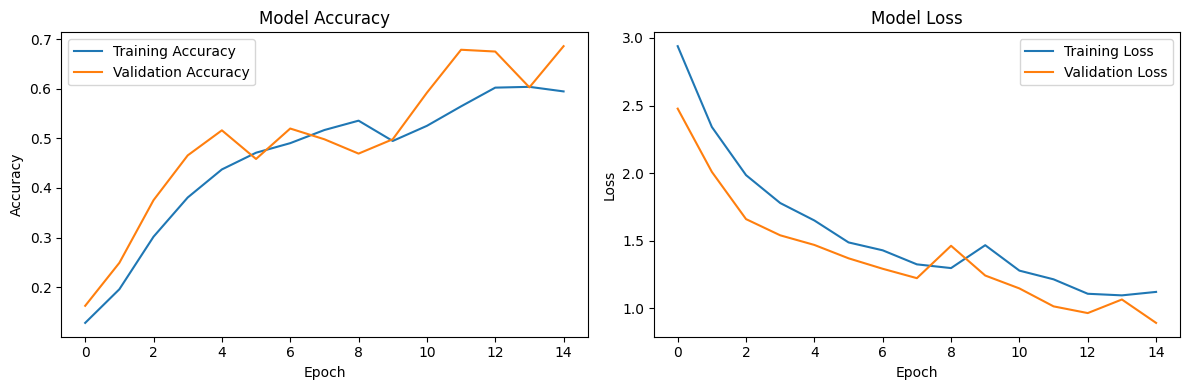

In [ ]:

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("Model Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()


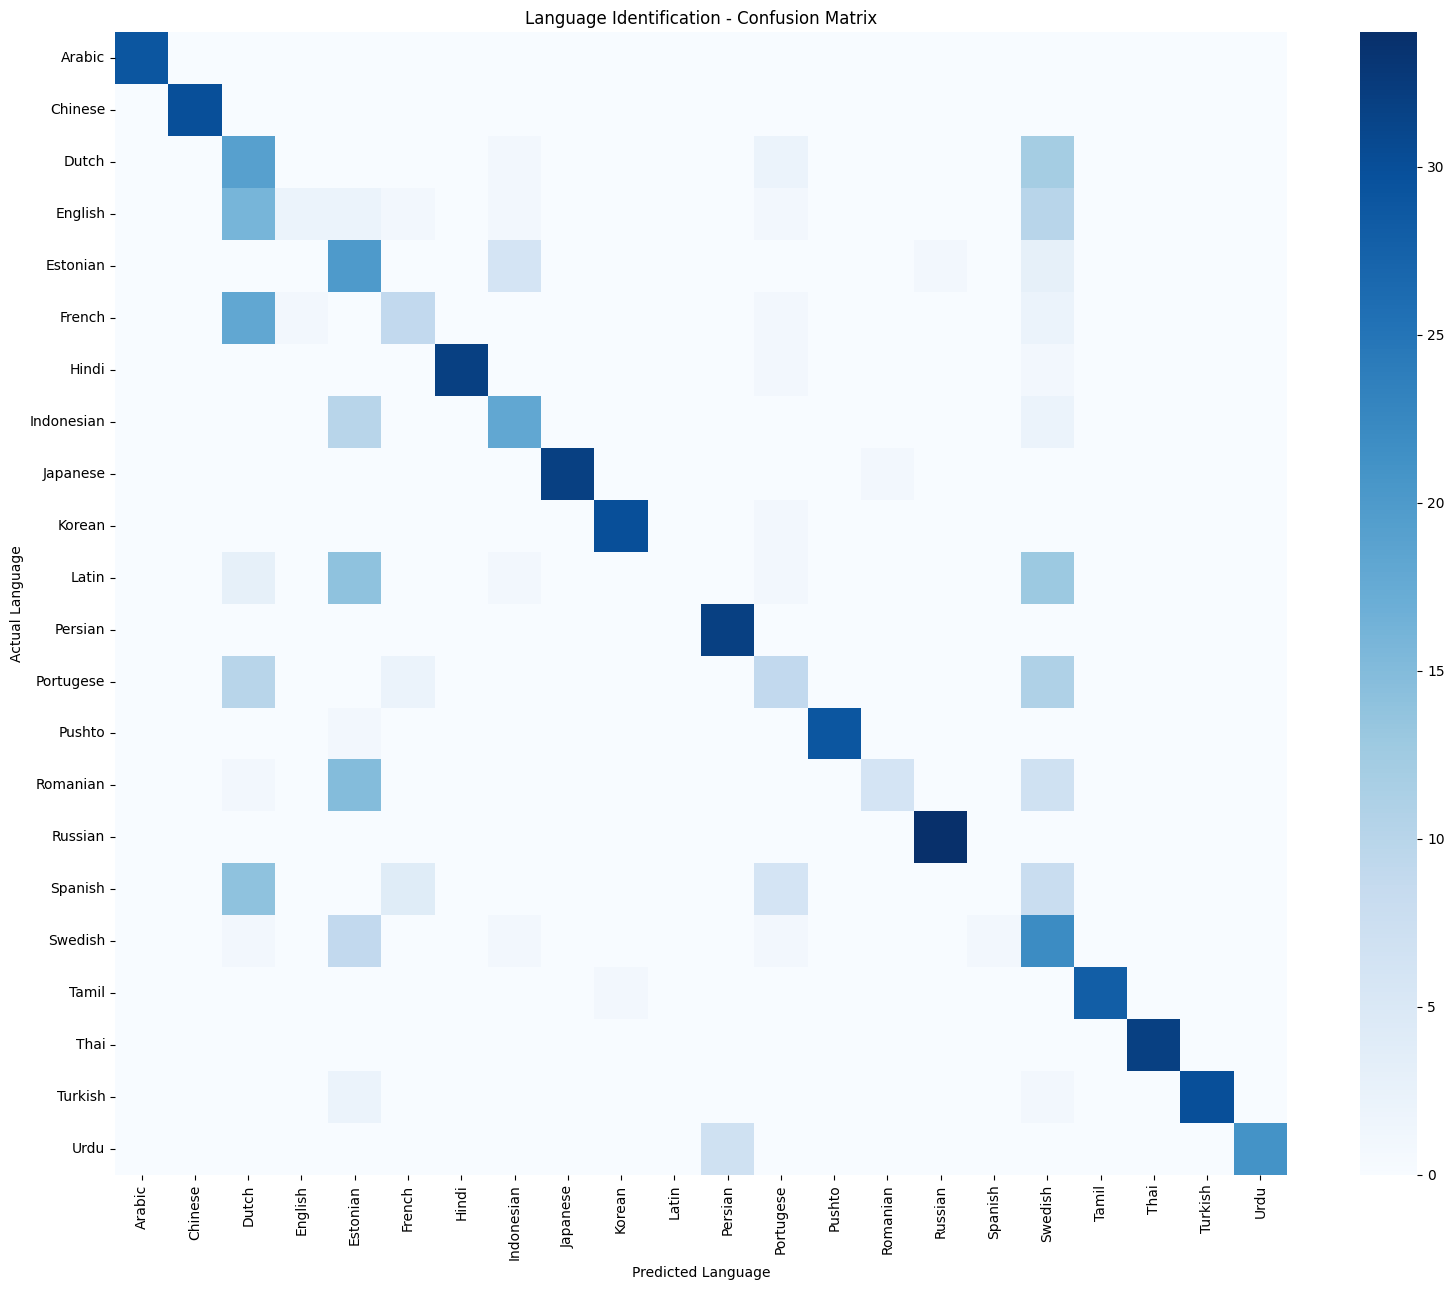

In [ ]:

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=np.arange(num_classes)
)

plt.figure(figsize=(16, 13))
sns.heatmap(
    cm,
    cmap="Blues",
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)
plt.title("Language Identification - Confusion Matrix")
plt.xlabel("Predicted Language")
plt.ylabel("Actual Language")
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()


In [ ]:

for i in range(min(15, len(X_test_text))):
    actual = label_encoder.inverse_transform([y_test[i]])[0]
    predicted = label_encoder.inverse_transform([y_pred[i]])[0]

    print("Text:", X_test_text[i][:120])
    print("Actual language:", actual)
    print("Predicted language:", predicted)
    print("-" * 60)


Text: रुधिर में प्लाज़्मा लाल रुधिर कोशिकाएँ श्वेत रुधिर कोशिकाएँ आदि रहती हैं। मानव के एक घन मिमि रुधिर में  लाल रुधिर कोशिका
Actual language: Hindi
Predicted language: Hindi
------------------------------------------------------------
Text: miha zupan nacido el  de septiembre de  en kranj eslovenia es un jugador de baloncesto esloveno con  de estatura su pues
Actual language: Spanish
Predicted language: Portugese
------------------------------------------------------------
Text: mathematical economic is an approach analysis in which the economists make use of mathematical symbols in the statment o
Actual language: Pushto
Predicted language: Estonian
------------------------------------------------------------
Text: londen werd op  juli  in singapore door het ioc gekozen als de gastheer voor de olympische spelen van  andere kandidaten
Actual language: Dutch
Predicted language: Dutch
------------------------------------------------------------
Text: 년 대구의 지역내 총생산grdp은 조천억 원이며 실질성장률은 이다